# 07. 데이터 전처리 ② 이상치 처리와 Feature Engineering

**AICE Associate 학습 7단계**

### 학습 목표
1. 이상치를 탐지(IQR, Z-score, 도메인 기준)하고 삭제·대체할 수 있다.
2. 범주형 변수를 숫자로 바꾸는 인코딩(Label / One-Hot)을 할 수 있다.
3. 파생변수를 만들고, 학습/검증 데이터를 분리할 수 있다.
4. 스케일링(Standard / MinMax / Robust)을 **올바른 순서(fit은 학습 데이터에만)** 로 적용할 수 있다.

> 시험 전처리 문항의 전형적인 흐름: **이상치 제거 → 결측치 처리 → 원-핫 인코딩 → train_test_split → 스케일링**

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


In [2]:
df = pd.read_csv('sc_cust_info_txn_v1.5.csv')
# 06번에서 배운 방식으로 결측치 먼저 처리
df = df.dropna(subset=['cust_class', 'sex_type'])
for col in ['age', 'r3m_avg_bill_amt', 'r3m_A_avg_arpu_amt']:
    df[col] = df[col].fillna(df[col].median())
df = df.reset_index(drop=True)
print(df.shape, df.isnull().sum().sum())

(9687, 10) 0


---
## 1. 이상치 탐지

### 1-1. 기초 통계와 boxplot

In [3]:
df.describe().T[['min', '25%', '50%', '75%', 'max']]

,min,25%,50%,75%,max
age,0.00,37.000,45.000,53.00,999.00
efct_svc_count,1.00,1.000,2.000,2.00,60.00
r3m_avg_bill_amt,956.10,14271.740,19601.045,26159.65,1199480.78
r3m_A_avg_arpu_amt,232.95,11670.895,16355.200,22087.00,71217.42
r3m_B_avg_arpu_amt,0.00,0.000,2051.180,4791.47,35582.79


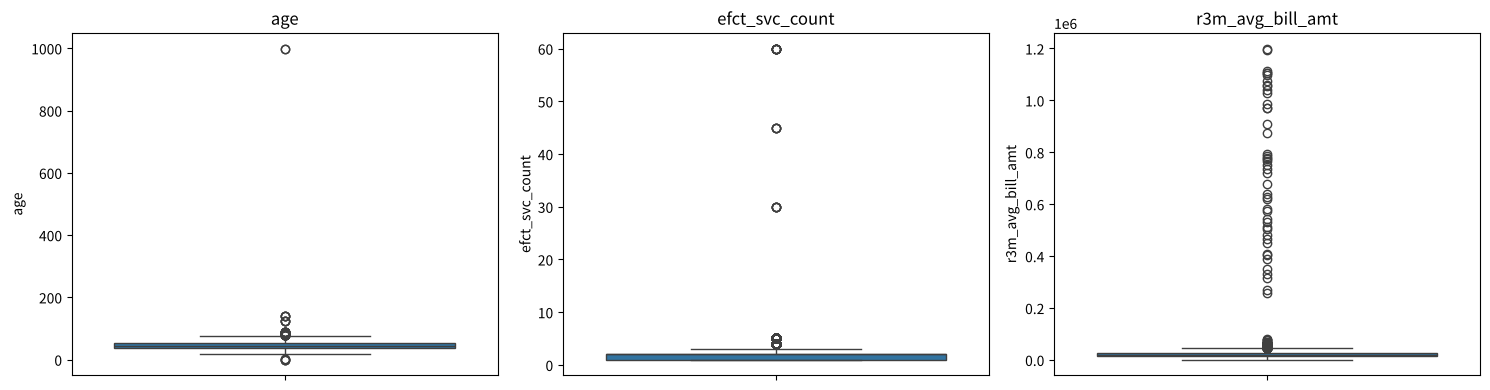

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['age'], ax=axes[0])
sns.boxplot(y=df['efct_svc_count'], ax=axes[1])
sns.boxplot(y=df['r3m_avg_bill_amt'], ax=axes[2])
for ax, t in zip(axes, ['age', 'efct_svc_count', 'r3m_avg_bill_amt']):
    ax.set_title(t)
plt.tight_layout()
plt.show()

### 1-2. IQR(사분위 범위) 방법 ★ 시험 단골

boxplot의 수염(whisker) 바깥 점이 IQR 기준 이상치입니다.

- Q1 = 25% 분위수, Q3 = 75% 분위수, **IQR = Q3 − Q1**
- **lower fence = Q1 − 1.5 × IQR**
- **upper fence = Q3 + 1.5 × IQR**
- 이 범위를 벗어나면 이상치

In [5]:
q1 = df['r3m_avg_bill_amt'].quantile(0.25)
q3 = df['r3m_avg_bill_amt'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print(f"Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}")
print(f"lower_fence={lower_fence:.1f}, upper_fence={upper_fence:.1f}")

outliers = df[(df['r3m_avg_bill_amt'] > upper_fence) | (df['r3m_avg_bill_amt'] < lower_fence)]
print("이상치 개수:", len(outliers))

Q1=14271.7, Q3=26159.7, IQR=11887.9
lower_fence=-3560.1, upper_fence=43991.5
이상치 개수: 260


In [6]:
# 재사용할 수 있게 함수로
def iqr_fence(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in ['age', 'efct_svc_count', 'r3m_avg_bill_amt', 'r3m_A_avg_arpu_amt', 'r3m_B_avg_arpu_amt']:
    lo, hi = iqr_fence(df[col])
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col:22s} lower={lo:10.1f} upper={hi:10.1f} 이상치={n}")

age                    lower=      13.0 upper=      77.0 이상치=83
efct_svc_count         lower=      -0.5 upper=       3.5 이상치=967
r3m_avg_bill_amt       lower=   -3560.1 upper=   43991.5 이상치=260
r3m_A_avg_arpu_amt     lower=   -3953.3 upper=   37711.2 이상치=301
r3m_B_avg_arpu_amt     lower=   -7187.2 upper=   11978.7 이상치=298


### 1-3. Z-score 방법

평균에서 표준편차의 몇 배 떨어져 있는지로 판단합니다. 보통 |z| > 3 이면 이상치로 봅니다.

In [7]:
z = (df['r3m_avg_bill_amt'] - df['r3m_avg_bill_amt'].mean()) / df['r3m_avg_bill_amt'].std()
print("|z| > 3 인 행:", (z.abs() > 3).sum())

|z| > 3 인 행: 45


### 1-4. 도메인 지식 기준

통계 기준보다 **상식**이 더 정확할 때가 많습니다. 예) 나이는 10~100세, 서비스 수는 10개 이하.
(샘플 문항 회귀편 5번: "평균시속이 300 이상인 행을 삭제하세요")

In [8]:
print(df[(df['age'] < 10) | (df['age'] > 100)]['age'].value_counts())
print(df[df['efct_svc_count'] > 10]['efct_svc_count'].value_counts())

age
140.0    4
125.0    4
0.0      3
999.0    2
1.0      2
Name: count, dtype: int64
efct_svc_count
60    9
30    5
45    4
Name: count, dtype: int64


---
## 2. 이상치 처리

### 2-1. 삭제 (샘플 문항 분류편 5번 패턴)

In [9]:
data_temp = df.drop(df[(df['r3m_avg_bill_amt'] > upper_fence) | (df['r3m_avg_bill_amt'] < lower_fence)].index, axis=0)
data_temp = data_temp[(data_temp['age'] >= 10) & (data_temp['age'] <= 100)]
data_temp = data_temp[data_temp['efct_svc_count'] <= 10]
data_temp.reset_index(drop=True, inplace=True)
print(df.shape, '->', data_temp.shape)

(9687, 10) -> (9397, 10)


### 2-2. 대체 (값 자르기 / 다른 값으로 바꾸기)

데이터를 버리기 아까울 때는 경계값으로 자르거나(clipping, winsorizing) 중앙값 등으로 바꿉니다.

In [10]:
df_clip = df.copy()
lo, hi = iqr_fence(df_clip['r3m_avg_bill_amt'])
df_clip['r3m_avg_bill_amt'] = df_clip['r3m_avg_bill_amt'].clip(lower=lo, upper=hi)
print(df_clip['r3m_avg_bill_amt'].max(), hi)

# 비정상 나이를 중앙값으로 대체
med = df_clip.loc[df_clip['age'].between(10, 100), 'age'].median()
df_clip.loc[~df_clip['age'].between(10, 100), 'age'] = med
df_clip['age'].describe()

43991.515 43991.515


count    9687.000000
mean       45.112212
std        12.448005
min        18.000000
25%        37.000000
50%        45.000000
75%        53.000000
max        90.000000
Name: age, dtype: float64

### 2-3. 로그 변환

오른쪽으로 길게 치우친 분포(금액 등)는 `np.log1p`로 변환하면 정규분포에 가까워지고 이상치 영향이 줄어듭니다.

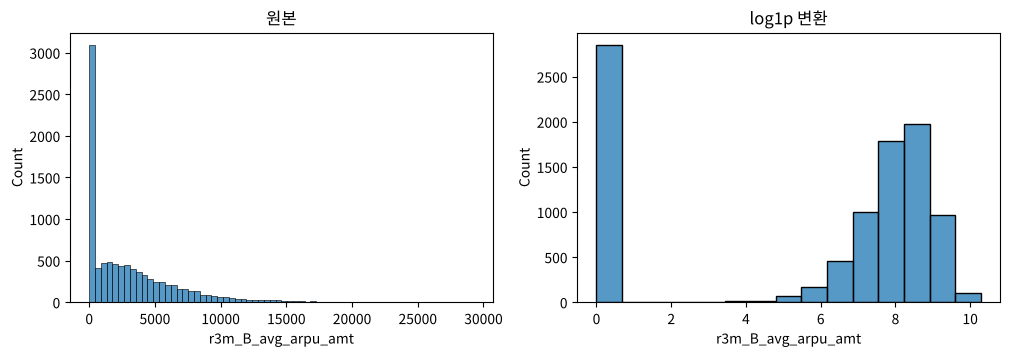

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(data_temp['r3m_B_avg_arpu_amt'], ax=axes[0]).set_title('원본')
sns.histplot(np.log1p(data_temp['r3m_B_avg_arpu_amt']), ax=axes[1]).set_title('log1p 변환')
plt.show()

---
## 3. Feature Engineering: 파생변수 만들기

In [12]:
fe = data_temp.copy()
fe['A_ratio'] = fe['r3m_A_avg_arpu_amt'] / fe['r3m_avg_bill_amt']           # 청구액 중 A상품 비중
fe['has_B'] = (fe['r3m_B_avg_arpu_amt'] > 0).astype(int)                     # B상품 이용 여부
fe['risk_flag'] = ((fe['dt_stop_yn'] == 'Y') | (fe['npay_yn'] == 'Y')).astype(int)
fe['age_band'] = pd.cut(fe['age'], bins=[0, 29, 39, 49, 59, 120], labels=['~20s', '30s', '40s', '50s', '60s~'])
fe[['A_ratio', 'has_B', 'risk_flag', 'age_band']].head()

,A_ratio,has_B,risk_flag,age_band
0,0.462424,1,0,60s~
1,1.041714,1,1,50s
2,0.760579,1,1,40s
3,0.956761,0,1,50s
4,0.827338,1,0,~20s


In [13]:
fe.groupby('risk_flag')['termination_yn'].value_counts(normalize=True).unstack()

termination_yn,N,Y
risk_flag,,
0,0.921526,0.078474
1,0.443548,0.556452


---
## 4. 인코딩: 범주형 → 숫자

머신러닝 모델은 문자열을 직접 학습할 수 없습니다.

| 방법 | 설명 | 사용처 |
|---|---|---|
| 직접 매핑 `map({'Y':1,'N':0})` | 이진 범주 | Y/N, Yes/No |
| `LabelEncoder` | 범주마다 0,1,2,... 정수 부여 | **타깃(y)** 인코딩, 트리 모델 |
| 원-핫 인코딩 `pd.get_dummies` | 범주마다 0/1 컬럼 생성 | **입력 변수(X)**, 선형/딥러닝 모델 |

In [14]:
# 1) 직접 매핑
enc = fe.copy()
for col in ['dt_stop_yn', 'npay_yn', 'termination_yn']:
    enc[col] = enc[col].map({'Y': 1, 'N': 0})
enc[['dt_stop_yn', 'npay_yn', 'termination_yn']].head(3)

,dt_stop_yn,npay_yn,termination_yn
0,0,0,0
1,0,1,0
2,0,1,0


In [15]:
# 2) LabelEncoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
enc['sex_code'] = le.fit_transform(enc['sex_type'])
print(le.classes_)                       # 인덱스 순서대로 0, 1, ...
enc[['sex_type', 'sex_code']].head(3)

['F' 'M']


,sex_type,sex_code
0,F,0
1,M,1
2,M,1


In [16]:
# 3) 원-핫 인코딩 ★ 시험 단골 (pd.get_dummies(data=..., columns=[...]))
enc = enc.drop(columns=['sex_code', 'age_band'])
enc_oh = pd.get_dummies(data=enc, columns=['cust_class', 'sex_type'])
print(enc.shape, '->', enc_oh.shape)
enc_oh.head(3)

(9397, 13) -> (9397, 21)


,age,efct_svc_count,dt_stop_yn,npay_yn,r3m_avg_bill_amt,r3m_A_avg_arpu_amt,r3m_B_avg_arpu_amt,termination_yn,A_ratio,has_B,...,cust_class_A,cust_class_B,cust_class_C,cust_class_D,cust_class_E,cust_class_F,cust_class_G,cust_class_H,sex_type_F,sex_type_M
0,61.0,2,0,0,7426.72,3434.29,2846.25,0,0.462424,1,...,False,True,False,False,False,False,False,False,True,False
1,55.0,1,0,1,23914.03,24911.58,656.88,0,1.041714,1,...,False,False,False,False,True,False,False,False,False,True
2,45.0,4,0,1,24819.29,18877.02,4975.65,0,0.760579,1,...,False,False,False,True,False,False,False,False,False,True


In [17]:
enc_oh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9397 entries, 0 to 9396
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 9397 non-null   float64
 1   efct_svc_count      9397 non-null   int64  
 2   dt_stop_yn          9397 non-null   int64  
 3   npay_yn             9397 non-null   int64  
 4   r3m_avg_bill_amt    9397 non-null   float64
 5   r3m_A_avg_arpu_amt  9397 non-null   float64
 6   r3m_B_avg_arpu_amt  9397 non-null   float64
 7   termination_yn      9397 non-null   int64  
 8   A_ratio             9397 non-null   float64
 9   has_B               9397 non-null   int64  
 10  risk_flag           9397 non-null   int64  
 11  cust_class_A        9397 non-null   bool   
 12  cust_class_B        9397 non-null   bool   
 13  cust_class_C        9397 non-null   bool   
 14  cust_class_D        9397 non-null   bool   
 15  cust_class_E        9397 non-null   bool   
 16  cust_c

In [18]:
# drop_first=True: 첫 번째 범주 컬럼을 빼서 다중공선성 방지 (선형모델에서 선호)
# dtype=int: True/False 대신 1/0
pd.get_dummies(enc[['cust_class']], drop_first=True, dtype=int).head(3)

,cust_class_B,cust_class_C,cust_class_D,cust_class_E,cust_class_F,cust_class_G,cust_class_H
0,1,0,0,0,0,0,0
1,0,0,0,1,0,0,0
2,0,0,1,0,0,0,0


In [19]:
# object 컬럼 전체를 원-핫 인코딩하는 방법 (샘플 문항 회귀편 7번)
obj_cols = fe.select_dtypes(include='object').columns.tolist()
print(obj_cols)

['cust_class', 'sex_type', 'dt_stop_yn', 'npay_yn', 'termination_yn']


---
## 5. 학습/검증 데이터 분리: `train_test_split` ★

- `test_size` : 검증 데이터 비율 (예: 0.2 → 80:20)
- `random_state` : 난수 시드 (재현성) — **문항에서 지정한 값 그대로!**
- `stratify=y` : 학습/검증의 **타깃 비율을 동일하게** (분류 문제에서 사용)

In [20]:
from sklearn.model_selection import train_test_split

X = enc_oh.drop('termination_yn', axis=1)
y = enc_oh['termination_yn']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_valid.shape)
print(y_train.mean().round(4), y_valid.mean().round(4))     # stratify 덕분에 비율이 같음

(6577, 20) (2820, 20)
0.1856 0.1858


---
## 6. 스케일링 ★ 시험 단골

변수마다 단위가 달라(나이 ~100 vs 금액 ~100,000) 거리 기반 모델·딥러닝이 큰 값에 끌려가는 것을 막습니다.

| 스케일러 | 변환 | 특징 |
|---|---|---|
| `StandardScaler` | (x − 평균) / 표준편차 | 평균 0, 표준편차 1 |
| `MinMaxScaler` | (x − 최소) / (최대 − 최소) | 0~1 범위 |
| `RobustScaler` | (x − 중앙값) / IQR | **이상치에 강함** |

> ⚠️ **가장 많이 나오는 오류 정정 문제**
> - 학습 데이터: `fit_transform(X_train)` (기준을 학습 + 변환)
> - 검증 데이터: `transform(X_valid)` (학습 데이터 기준 그대로 적용)
> - 검증 데이터에 `fit_transform`을 쓰면 **데이터 누수(leakage)** 이자 오답입니다.

In [21]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

ss = StandardScaler()
X_train_ss = ss.fit_transform(X_train)
X_valid_ss = ss.transform(X_valid)
print(type(X_train_ss), X_train_ss.shape)
print("학습 평균:", X_train_ss.mean().round(3), "/ 검증 최댓값 반올림:", round(np.max(X_valid_ss)))

<class 'numpy.ndarray'> (6577, 20)
학습 평균: 0.0 / 검증 최댓값 반올림: 13


In [22]:
mm = MinMaxScaler()
X_train_mm = mm.fit_transform(X_train)
X_valid_mm = mm.transform(X_valid)
print(X_train_mm.min(), X_train_mm.max(), "| 검증 최댓값:", X_valid_mm.max().round(3))   # 검증은 1을 넘을 수도 있음

0.0 1.0000000000000002 | 검증 최댓값: 1.0


In [23]:
rs = RobustScaler()
X_train_rs = rs.fit_transform(X_train)
X_valid_rs = rs.transform(X_valid)
print(round(np.max(X_valid_rs)))

12


In [24]:
# 스케일링 결과를 다시 DataFrame으로 보고 싶다면
pd.DataFrame(X_train_ss, columns=X.columns).describe().T[['mean', 'std']].head()

,mean,std
age,7.346344e-17,1.000076
efct_svc_count,-1.674534e-17,1.000076
dt_stop_yn,-1.620517e-17,1.000076
npay_yn,-9.182930e-18,1.000076
r3m_avg_bill_amt,3.643463e-16,1.000076


---
## ✏️ 연습문제 (`cust_data1.csv` 사용)

In [25]:
data = pd.read_csv('cust_data1.csv')
data.describe()

,age,service,avg_bill,A_bill,B_bill
count,9845.000000,9930.000000,9870.000000,9905.000000,9930.000000
mean,45.150127,1.909466,21813.605677,17821.274698,3121.128966
std,12.915434,1.060826,26928.542847,8905.909489,3649.589256
min,18.000000,1.000000,1000.000000,239.540500,0.000000
25%,36.000000,1.000000,14078.892050,11461.334800,0.000000
50%,45.000000,2.000000,19514.495900,16369.778000,2063.190900
75%,54.000000,2.000000,26189.113350,22486.900500,4815.524275
max,150.000000,5.000000,878343.613600,78029.595700,36790.799400


**문제 1.** `avg_bill` 컬럼에 대해 IQR 방식으로 upper fence와 lower fence를 구하고, 범위를 벗어나는 행을 삭제한 결과를 `data_temp`에 저장하세요. index도 초기화하세요. 삭제된 행의 개수를 `답안1`에 저장하세요. (결측치는 이상치로 보지 않고 남겨둡니다)

In [26]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 2.** `data_temp`에서 `age`가 100보다 큰 행을 삭제하고, 결측치가 있는 행을 모두 삭제하여 `data_na`에 저장하세요.

In [27]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 3.** `data_na`의 `termination` 을 Y→1, N→0 으로 바꾸고, object형 컬럼 전체를 원-핫 인코딩하여 `data_preset`에 저장하세요.

In [28]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 4.** `termination`을 y, 나머지를 X로 하여 80:20, `random_state=7`, 타깃 비율 유지 옵션으로 분리하세요.

In [29]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 5.** 아래 코드의 오류를 정정하고, 스케일링된 검증데이터의 최댓값을 반올림하여 `답안5`에 저장하세요.
```python
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()
X_train = mm.fit_transform(X_train)
X_valid = mm.fit_transform(X_valid)
round(np.max(X_valid))
```

In [30]:
# 아래의 코드를 정정하고 실행하세요.

---
## ✅ 정답 및 해설

In [31]:
# 문제 1
q1 = data['avg_bill'].quantile(0.25)
q3 = data['avg_bill'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
data_temp = data.drop(data[(data['avg_bill'] > upper_fence) | (data['avg_bill'] < lower_fence)].index, axis=0)
data_temp.reset_index(drop=True, inplace=True)
답안1 = len(data) - len(data_temp)
print(답안1)

# 문제 2
data_na = data_temp[~(data_temp['age'] > 100)]     # NaN은 비교 결과 False이므로 ~ 로 남겨둔 뒤
data_na = data_na.dropna().reset_index(drop=True)  # dropna로 삭제
print(data_na.shape, data_na.isnull().sum().sum())

# 문제 3
data_na['termination'] = data_na['termination'].map({'Y': 1, 'N': 0})
obj_cols = data_na.select_dtypes(include='object').columns
data_preset = pd.get_dummies(data=data_na, columns=obj_cols)
data_preset.info()

239
(9480, 10) 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9480 entries, 0 to 9479
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          9480 non-null   float64
 1   service      9480 non-null   int64  
 2   avg_bill     9480 non-null   float64
 3   A_bill       9480 non-null   float64
 4   B_bill       9480 non-null   float64
 5   termination  9480 non-null   int64  
 6   class_A      9480 non-null   bool   
 7   class_B      9480 non-null   bool   
 8   class_C      9480 non-null   bool   
 9   class_D      9480 non-null   bool   
 10  class_E      9480 non-null   bool   
 11  class_F      9480 non-null   bool   
 12  class_G      9480 non-null   bool   
 13  class_H      9480 non-null   bool   
 14  sex_F        9480 non-null   bool   
 15  sex_M        9480 non-null   bool   
 16  stop_N       9480 non-null   bool   
 17  stop_Y       9480 non-null   bool   
 18  npay_N       9480 non-null   bo

In [32]:
# 문제 4
from sklearn.model_selection import train_test_split
X = data_preset.drop('termination', axis=1)
y = data_preset['termination']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)
print(X_train.shape, X_valid.shape)

# 문제 5 : 검증 데이터는 transform 만!
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()
X_train = mm.fit_transform(X_train)
X_valid = mm.transform(X_valid)
답안5 = round(np.max(X_valid))
print(답안5)

(7584, 19) (1896, 19)
1
